# Recursive Forecasting

This notebook runs recursive forecasting from a completed benchmark run directory. The run directory must contain `resolved_run.json` and `checkpoint_best.pt`.

For `num_steps > 0`, the rollout downloads temporary Google Earth Engine rasters for each recursive step, so Earth Engine credentials and the study artifacts need to be available. If the raster stack fails with a `CXXABI`/`libstdc++` error, start Jupyter with:

```bash
cd /data/vision/beery/scratch/justin/movebench
LD_LIBRARY_PATH=/data/vision/beery/scratch/justin/micromamba/envs/movebench/lib:${LD_LIBRARY_PATH:-} /data/vision/beery/scratch/justin/micromamba/envs/movebench/bin/jupyter lab
```


In [ ]:
from __future__ import annotations

import os
import sys
from pathlib import Path

def find_repo_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / "pyproject.toml").exists() and (path / "movebench").is_dir():
            return path
    raise RuntimeError(f"Could not find repo root from {start}")

REPO_ROOT = find_repo_root(Path.cwd().resolve())
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

REPO_ROOT


In [ ]:
import pandas as pd
import torch

from movebench.forecast import RecursiveForecastConfig, run_recursive_forecast


## Configuration

Update `RUN_DIR` to point at the trained run you want to forecast from. The default below is only an example completed local run found under `results/bench/runs`; it is not a preferred study. Supported trained methods are `issf_linear`, `issf_mlp`, `deepssf`, and `moveformer`.


In [ ]:
RUN_DIR = Path(
    "results/bench/runs/"
    "study=Naniwadekar_35a868e5_raw_merged_Rhyticeros_undulatus__ts=1d__cov=all__method=issf_linear__seed=0__k=8cc8ab831fd0c5e9"
)

SPLIT_KEY = "test_temporal"
TEST_POINT_INDEX = 0
NUM_TRAJECTORIES = 100
NUM_STEPS = 25
SEED = 0
OUT_DIR = Path("results/recursive_forecasts")

RUN_DIR.exists(), RUN_DIR


## Fast Smoke Test

`num_steps=0` only resolves the requested seed point. It does not run a recursive rollout or download new rasters.


In [ ]:
smoke = run_recursive_forecast(
    RecursiveForecastConfig(
        run_dir=RUN_DIR,
        split_key=SPLIT_KEY,
        test_point_index=TEST_POINT_INDEX,
        num_trajectories=min(NUM_TRAJECTORIES, 2),
        num_steps=0,
        seed=SEED,
    )
)

print(smoke.run_key)
print(smoke.method, smoke.split_key, smoke.seed_point_id_start)
print(smoke.lon.shape, smoke.lat.shape, smoke.timestamp_ns.shape)

pd.DataFrame(
    {
        "lon": smoke.lon[:, 0].numpy(),
        "lat": smoke.lat[:, 0].numpy(),
        "timestamp_ns": smoke.timestamp_ns[:, 0].numpy(),
    }
)


## Run Recursive Rollout

This is the expensive cell. It samples `NUM_TRAJECTORIES` recursive paths for `NUM_STEPS` forecast steps.


In [ ]:
import ee
ee.Authenticate(auth_mode='notebook')

ee.Initialize()

In [ ]:
result = run_recursive_forecast(
    RecursiveForecastConfig(
        run_dir=RUN_DIR,
        split_key=SPLIT_KEY,
        test_point_index=TEST_POINT_INDEX,
        num_trajectories=NUM_TRAJECTORIES,
        num_steps=NUM_STEPS,
        seed=SEED,
    )
)

print(result.run_key)
print(result.method, result.split_key, result.seed_point_id_start)
print(result.lon.shape, result.lat.shape, result.timestamp_ns.shape)
print(result.step_time_s, result.pixel_size_m)


## Save Outputs

The `.pt` file preserves tensors and metadata. The `.csv` file is a flattened trajectory table for quick plotting or GIS workflows.


In [ ]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
stem = f"{result.run_key}__{result.split_key}__point={result.seed_point_id_start}"
pt_path = OUT_DIR / f"{stem}.pt"
csv_path = OUT_DIR / f"{stem}.csv"

torch.save(
    {
        "run_key": result.run_key,
        "method": result.method,
        "split_key": result.split_key,
        "seed_point_id_start": result.seed_point_id_start,
        "step_time_s": result.step_time_s,
        "pixel_size_m": result.pixel_size_m,
        "lon": result.lon,
        "lat": result.lat,
        "timestamp_ns": result.timestamp_ns,
        "sampled_row": result.sampled_row,
        "sampled_col": result.sampled_col,
    },
    pt_path,
)

n, t = result.lon.shape
df = pd.DataFrame(
    {
        "trajectory": [i for i in range(n) for _ in range(t)],
        "step": list(range(t)) * n,
        "lon": result.lon.reshape(-1).numpy(),
        "lat": result.lat.reshape(-1).numpy(),
        "timestamp_ns": result.timestamp_ns.reshape(-1).numpy(),
    }
)
df.to_csv(csv_path, index=False)

print(pt_path)
print(csv_path)
df.head()


## Quick Plot

This plots a small subset of sampled forecast paths in longitude/latitude space.


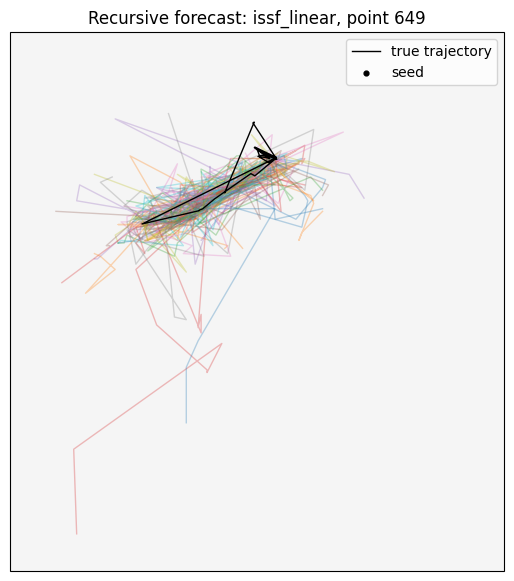

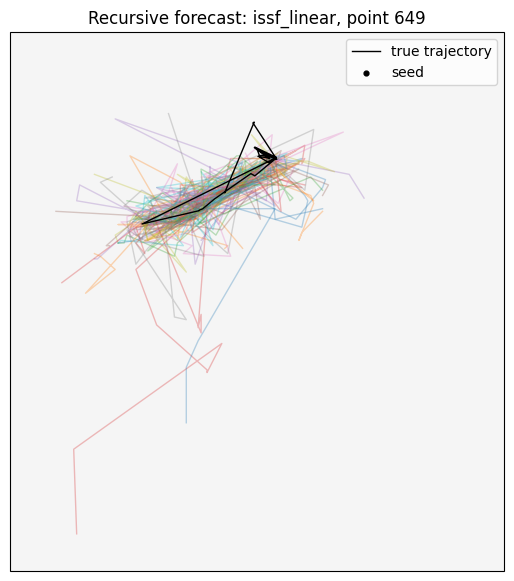

In [23]:
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import pandas as pd

from movebench.bench.run import load_saved_run_bundle
from movebench.trajectories import (
    INDIVIDUAL_COL,
    LAT_COL,
    LON_COL,
    POINT_ID_COL,
    SET_COL,
    TIME_COL,
    load_trajectories_csv,
)

run_payload, resolved_artifacts = load_saved_run_bundle(RUN_DIR)
study_dir = Path(resolved_artifacts["study_dir"])
trajectories_path = Path(
    resolved_artifacts.get("trajectories_path") or study_dir / "trajectories.csv"
)
trajectories = load_trajectories_csv(trajectories_path)
seed_row = trajectories.loc[
    trajectories[POINT_ID_COL] == int(result.seed_point_id_start)
].iloc[0]
true_trajectory = trajectories.loc[
    (trajectories[INDIVIDUAL_COL] == seed_row[INDIVIDUAL_COL])
    & (trajectories[SET_COL] == result.split_key)
    & (trajectories[TIME_COL] >= seed_row[TIME_COL])
    & (trajectories[TIME_COL] <= pd.to_datetime(int(result.timestamp_ns[0, -1].item())))
].sort_values(TIME_COL)

plot_lon = pd.concat(
    [
        pd.Series(result.lon.reshape(-1).numpy()),
        true_trajectory[LON_COL].astype(float),
    ],
    ignore_index=True,
)
plot_lat = pd.concat(
    [
        pd.Series(result.lat.reshape(-1).numpy()),
        true_trajectory[LAT_COL].astype(float),
    ],
    ignore_index=True,
)
lon_pad = max(float(plot_lon.max() - plot_lon.min()) * 0.08, 0.01)
lat_pad = max(float(plot_lat.max() - plot_lat.min()) * 0.08, 0.01)

data_crs = ccrs.PlateCarree()
fig = plt.figure(figsize=(7, 7))
ax = plt.axes(projection=data_crs)
ax.set_extent(
    [
        float(plot_lon.min()) - lon_pad,
        float(plot_lon.max()) + lon_pad,
        float(plot_lat.min()) - lat_pad,
        float(plot_lat.max()) + lat_pad,
    ],
    crs=data_crs,
)
ax.add_feature(cfeature.LAND.with_scale("110m"), facecolor="0.96", edgecolor="none", zorder=0)
ax.add_feature(cfeature.OCEAN.with_scale("110m"), facecolor="white", edgecolor="none", zorder=0)
ax.coastlines(resolution="110m", linewidth=0.5, color="0.45", zorder=1)


ax.plot(
    true_trajectory[LON_COL].to_numpy()[:25],
    true_trajectory[LAT_COL].to_numpy()[:25],
    color="black",
    linewidth=1.0,
    label="true trajectory",
    transform=data_crs,
    zorder=3,
)
ax.scatter(
    result.lon[:, 0].numpy(),
    result.lat[:, 0].numpy(),
    s=12,
    color="black",
    label="seed",
    transform=data_crs,
    # zorder=4,
)

for i in range(min(50, result.lon.shape[0])):
    ax.plot(
        result.lon[i].numpy(),
        result.lat[i].numpy(),
        # color="tab:blue",
        alpha=0.3,
        linewidth=1.0,
        transform=data_crs,
    )

ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title(f"Recursive forecast: {result.method}, point {result.seed_point_id_start}")
ax.legend()
fig


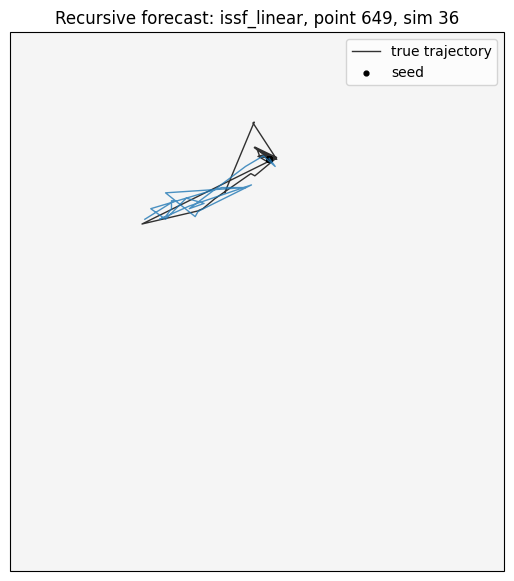

In [29]:
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import pandas as pd

from movebench.bench.run import load_saved_run_bundle
from movebench.trajectories import (
    INDIVIDUAL_COL,
    LAT_COL,
    LON_COL,
    POINT_ID_COL,
    SET_COL,
    TIME_COL,
    load_trajectories_csv,
)

run_payload, resolved_artifacts = load_saved_run_bundle(RUN_DIR)
study_dir = Path(resolved_artifacts["study_dir"])
trajectories_path = Path(
    resolved_artifacts.get("trajectories_path") or study_dir / "trajectories.csv"
)
trajectories = load_trajectories_csv(trajectories_path)
seed_row = trajectories.loc[
    trajectories[POINT_ID_COL] == int(result.seed_point_id_start)
].iloc[0]
true_trajectory = trajectories.loc[
    (trajectories[INDIVIDUAL_COL] == seed_row[INDIVIDUAL_COL])
    & (trajectories[SET_COL] == result.split_key)
    & (trajectories[TIME_COL] >= seed_row[TIME_COL])
    & (trajectories[TIME_COL] <= pd.to_datetime(int(result.timestamp_ns[0, -1].item())))
].sort_values(TIME_COL)

plot_lon = pd.concat(
    [
        pd.Series(result.lon.reshape(-1).numpy()),
        true_trajectory[LON_COL].astype(float),
    ],
    ignore_index=True,
)
plot_lat = pd.concat(
    [
        pd.Series(result.lat.reshape(-1).numpy()),
        true_trajectory[LAT_COL].astype(float),
    ],
    ignore_index=True,
)
lon_pad = max(float(plot_lon.max() - plot_lon.min()) * 0.08, 0.01)
lat_pad = max(float(plot_lat.max() - plot_lat.min()) * 0.08, 0.01)

data_crs = ccrs.PlateCarree()
fig = plt.figure(figsize=(7, 7))
ax = plt.axes(projection=data_crs)
ax.set_extent(
    [
        float(plot_lon.min()) - lon_pad,
        float(plot_lon.max()) + lon_pad,
        float(plot_lat.min()) - lat_pad,
        float(plot_lat.max()) + lat_pad,
    ],
    crs=data_crs,
)
ax.add_feature(cfeature.LAND.with_scale("110m"), facecolor="0.96", edgecolor="none", zorder=0)
ax.add_feature(cfeature.OCEAN.with_scale("110m"), facecolor="white", edgecolor="none", zorder=0)
ax.coastlines(resolution="110m", linewidth=0.5, color="0.45", zorder=1)


ax.plot(
    true_trajectory[LON_COL].to_numpy()[:25],
    true_trajectory[LAT_COL].to_numpy()[:25],
    color="black",
    linewidth=1.0,
    label="true trajectory",
    transform=data_crs,
    alpha=0.8
    # zorder=3,
)
ax.scatter(
    result.lon[:, 0].numpy(),
    result.lat[:, 0].numpy(),
    s=12,
    color="black",
    label="seed",
    transform=data_crs,
    # zorder=4,
)

import random
# for i in range(min(50, result.lon.shape[0])):
i = random.randint(0, result.lon.shape[0])
ax.plot(
    result.lon[i].numpy(),
    result.lat[i].numpy(),
    # color="tab:blue",
    alpha=0.8,
    linewidth=1.0,
    transform=data_crs,
)


ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title(f"Recursive forecast: {result.method}, point {result.seed_point_id_start}, sim {i}")
ax.legend()
# fig
